# Assignment 20: Time Series Forecasting with Supervised Learning – Household Power Consumption

In this assignment I forecast household electricity consumption using supervised learning models: Linear Regression, Random Forest and Gradient Boosting (XGBoost). Time series data is not independent like the tabular data in earlier assignments: each value depends on previous values. So I turn the series into a supervised learning problem by creating lag features (past values used as predictors), and I split the data in time order so the models are always tested on future data.

Dataset:
- The power consumption dataset provided with the assignment (household_power_consumption.txt), which is the UCI "Individual Household Electric Power Consumption" dataset: https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption
- Content: electricity measurements of one household in France, recorded every minute from December 2006 to November 2010
- Target: Global_active_power, the household's total active power in kilowatts (kW). I will resample it to a daily average.

Note: the data file is about 127 MB, which is larger than GitHub's 100 MB file limit, so it is not included in the repository. It can be downloaded from the link above.

Steps I will follow:
1. Import libraries
2. Load the data, combine Date and Time into a datetime index, and handle missing values
3. Resample the minute data to daily averages and explore the series
4. Create lag features
5. Split the data in time order (first 80% train, last 20% test)
6. Seasonal decomposition (trend, seasonality and residual)
7. Train and evaluate Linear Regression, Random Forest and Gradient Boosting (XGBoost)
8. Compare the models using MSE and visualize forecasts against actual values
9. Report

## Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option("display.max_columns", None)
random_seed = 42

## Step 2: Load the Dataset and Set the Date as the Index

In [2]:
power = pd.read_csv("household_power_consumption.txt", sep=";", na_values="?", low_memory=False)
print("Raw shape:", power.shape)
display(power.head(3))

# Combine Date + Time into one datetime column and set it as the index
power["Datetime"] = pd.to_datetime(power["Date"] + " " + power["Time"], format="%d/%m/%Y %H:%M:%S")
power = power.drop(columns=["Date", "Time"]).set_index("Datetime").sort_index()

power.info()
print("\nTime range:", power.index.min(), "to", power.index.max())
print("Missing values per column:\n", power.isnull().sum())
print("Missing % (Global_active_power):", round(power["Global_active_power"].isnull().mean() * 100, 2))
print("Duplicate timestamps:", power.index.duplicated().sum())

Raw shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0


<class 'pandas.DataFrame'>
DatetimeIndex: 2075259 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 7 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float64
 1   Global_reactive_power  float64
 2   Voltage                float64
 3   Global_intensity       float64
 4   Sub_metering_1         float64
 5   Sub_metering_2         float64
 6   Sub_metering_3         float64
dtypes: float64(7)
memory usage: 126.7 MB

Time range: 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Missing values per column:
 Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64
Missing % (Global_active_power): 1.25
Duplicate timestamps: 0


### Interpretation: Loading the Data

The raw file has 2,075,259 rows, one per minute, from 16 December 2006 at 17:24 to 26 November 2010 at 21:02, almost four years of data. I combined the separate Date and Time columns into one datetime column and set it as the index, so the data can be handled as a time series. There are no duplicate timestamps.

The file uses "?" for missing readings, which I converted to real missing values when loading. All 7 measurement columns have exactly the same number of missing values (25,979, or 1.25% of minutes), which means entire readings are missing at those times, probably because the meter was not recording.

The first and last days are incomplete (the recording starts at 17:24 on the first day and stops at 21:02 on the last day). I will remove these partial days when I resample the data to daily values.

My target is Global_active_power, the total active power used by the household in kilowatts (kW).

## Step 3: Resample to Daily Averages, Handle Missing Values and Explore the Series

In [3]:
# 1. Daily average of Global_active_power, dropping the partial first and last days
minutes_per_day = power["Global_active_power"].resample("D").count()
daily = power["Global_active_power"].resample("D").mean().iloc[1:-1]
print("Daily points:", len(daily), "| from", daily.index.min().date(), "to", daily.index.max().date())
print("Days with fewer than 1,440 recorded minutes:", (minutes_per_day.iloc[1:-1] < 1440).sum())
print("Days completely missing (NaN after resampling):", daily.isnull().sum())

Daily points: 1440 | from 2006-12-17 to 2010-11-25
Days with fewer than 1,440 recorded minutes: 82
Days completely missing (NaN after resampling): 9


In [4]:
# 2. Fill completely missing days by time-based interpolation
daily = daily.interpolate(method="time")
print("Missing days after interpolation:", daily.isnull().sum())
display(daily.describe().round(3).to_frame("Daily avg kW").T)

Missing days after interpolation: 0


,count,mean,std,min,25%,50%,75%,max
Daily avg kW,1440.0,1.089,0.417,0.174,0.81,1.078,1.319,3.315


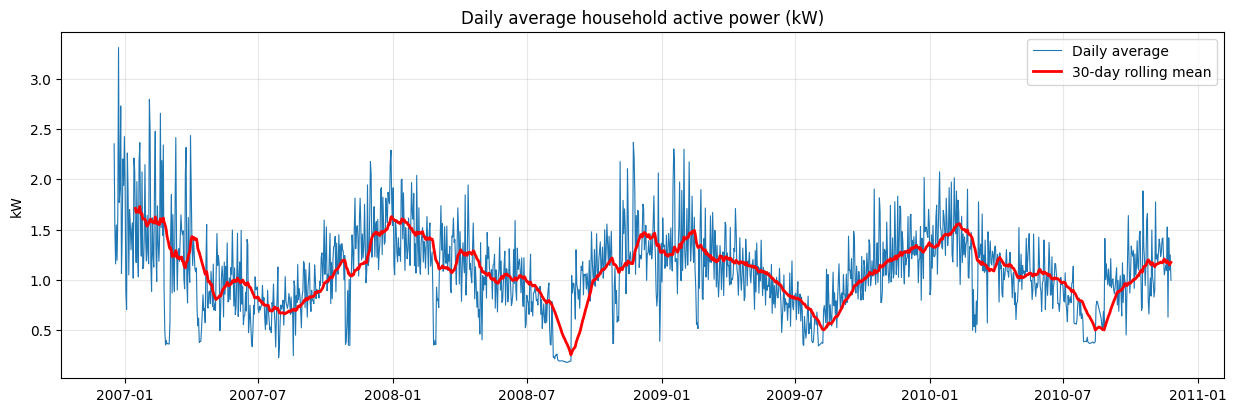

In [5]:
# 3. Plot the whole series with a 30-day rolling mean
plt.figure(figsize=(15, 4.5))
plt.plot(daily, linewidth=0.8, label="Daily average")
plt.plot(daily.rolling(30).mean(), color="red", linewidth=2, label="30-day rolling mean")
plt.title("Daily average household active power (kW)"); plt.ylabel("kW"); plt.legend(); plt.grid(alpha=0.3); plt.show()

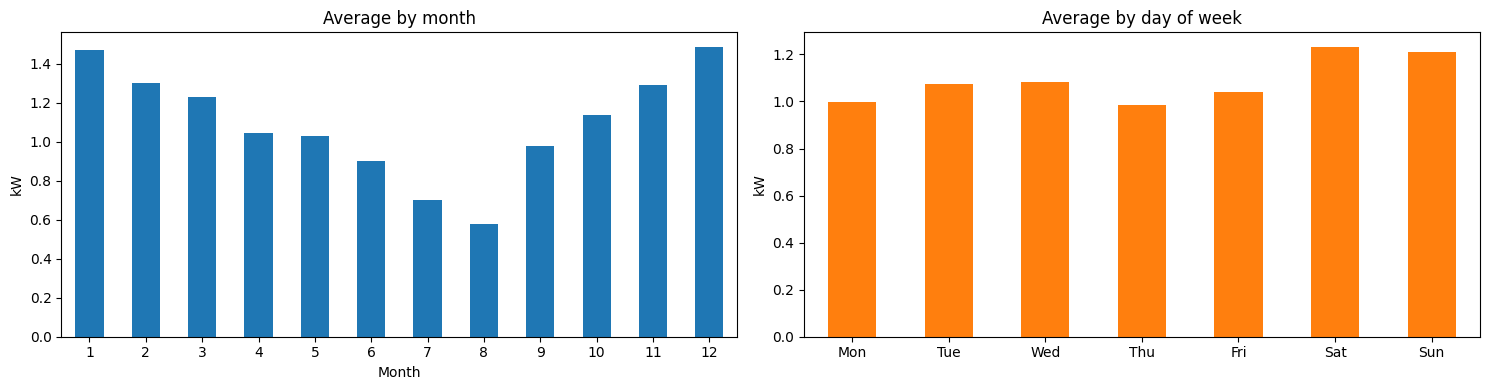

In [6]:
# 4. Patterns: by month and by day of the week
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
daily.groupby(daily.index.month).mean().plot(kind="bar", ax=axes[0], rot=0, color="tab:blue")
axes[0].set_title("Average by month"); axes[0].set_xlabel("Month"); axes[0].set_ylabel("kW")
dow = daily.groupby(daily.index.dayofweek).mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow.plot(kind="bar", ax=axes[1], rot=0, color="tab:orange")
axes[1].set_title("Average by day of week"); axes[1].set_ylabel("kW")
plt.tight_layout(); plt.show()

### Interpretation: Daily Series and Patterns

I resampled the minute data to daily averages and removed the two partial days. This left 1,440 days, from 17 December 2006 to 25 November 2010. 82 days had some missing minutes, and their averages use only the recorded minutes. 9 days were completely missing, and I filled them by time-based interpolation (a straight line between the neighbouring days), which suits a smooth series like daily electricity use. There are no missing values left.

The daily average power ranges from 0.17 to 3.32 kW, with a mean of 1.09 kW and a standard deviation of 0.42 kW.

Yearly seasonality:
The line chart and the 30-day rolling mean show the same wave every year: consumption is highest in winter (December 1.49 kW and January 1.47 kW on average) and lowest in summer (August 0.58 kW), probably because of heating and lighting in the colder, darker months. The deepest drops, to about 0.2 kW, happen in August, which suggests the household was away on summer holiday.

Weekly seasonality:
Consumption is higher at weekends (Saturday 1.23 kW and Sunday 1.21 kW) than on weekdays (about 0.99 to 1.08 kW), probably because people spend more time at home.

Trend:
There is no strong long-term upward or downward trend: the rolling mean rises and falls with the seasons but stays at a similar level across the four years. There is also a lot of day-to-day variation around the seasonal pattern, which will make exact daily forecasts difficult.

## Step 4: Create Lag Features and Split the Data into Training (First 80%) and Testing (Last 20%) Sets

In [7]:
# 1. Lag features (past values as predictors)
ts = pd.DataFrame({"power": daily})
for lag in [1, 2, 3, 7, 14]:
    ts[f"lag_{lag}"] = ts["power"].shift(lag)
ts["rolling_mean_7"] = ts["power"].shift(1).rolling(7).mean()

print("Rows with missing lags (start of the series):", ts.isnull().any(axis=1).sum())
ts = ts.dropna()
display(ts.head(3))

Rows with missing lags (start of the series): 14


,power,lag_1,lag_2,lag_3,lag_7,lag_14,rolling_mean_7
Datetime,,,,,,,
2006-12-31,2.426525,1.939709,2.204439,1.439332,1.770842,2.354486,1.864704
2007-01-01,1.909031,2.426525,1.939709,2.204439,1.904944,1.530435,1.958373
2007-01-02,0.881414,1.909031,2.426525,1.939709,2.732021,1.157079,1.958956


In [8]:
# 2. Correlation of each lag feature with the target
print("Correlation with today's power:\n", ts.corr()["power"].drop("power").round(3))

Correlation with today's power:
 lag_1             0.611
lag_2             0.480
lag_3             0.528
lag_7             0.542
lag_14            0.486
rolling_mean_7    0.669
Name: power, dtype: float64



Train: 1140 days (2006-12-31 to 2010-02-12)
Test:  286 days (2010-02-13 to 2010-11-25)


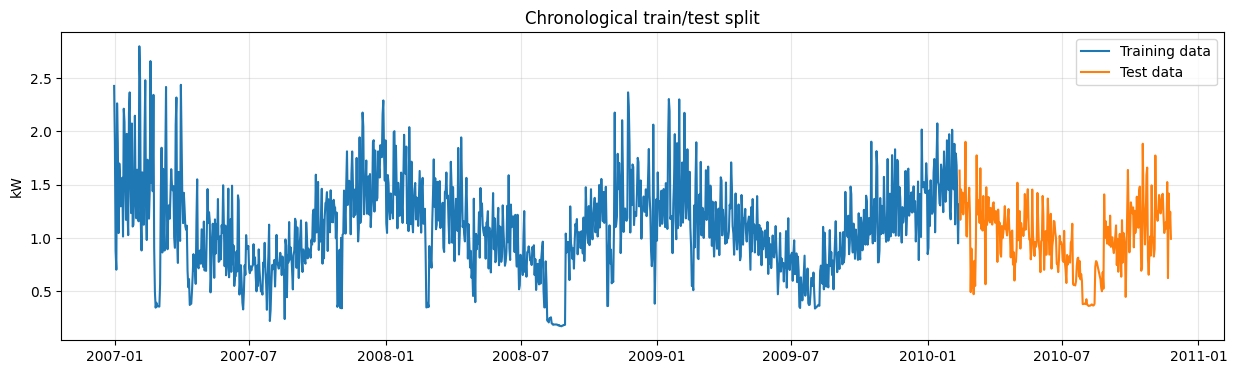

In [9]:
# 3. Chronological split: first 80% train, last 20% test (NO shuffling)
split = int(len(ts) * 0.8)
train, test = ts.iloc[:split], ts.iloc[split:]
features = [c for c in ts.columns if c != "power"]
X_train, y_train = train[features], train["power"]
X_test, y_test = test[features], test["power"]

print(f"\nTrain: {len(train)} days ({train.index.min().date()} to {train.index.max().date()})")
print(f"Test:  {len(test)} days ({test.index.min().date()} to {test.index.max().date()})")

plt.figure(figsize=(15, 4))
plt.plot(y_train, label="Training data"); plt.plot(y_test, label="Test data", color="tab:orange")
plt.title("Chronological train/test split"); plt.ylabel("kW"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### Interpretation: Lag Features and Train/Test Split

Lag features:
I created lag features using past values of the daily power: lag_1 (yesterday), lag_2, lag_3, lag_7 (the same weekday last week), lag_14 (two weeks ago), and rolling_mean_7 (the average of the previous 7 days, not including today). The first 14 days had no complete history, so I removed them, which left 1,426 days. In each row, the lag values are exactly the power values from the earlier days, so the time series is now a normal supervised learning table.

Correlation with today's power:
- rolling_mean_7 has the strongest correlation (0.669), so the recent average level is the best single predictor.
- lag_1 (yesterday) follows with 0.611.
- lag_7 (0.542) is more correlated than lag_2 (0.480) and lag_3 (0.528), which confirms the weekly pattern: the same weekday last week is a better guide than 2 or 3 days ago.
- lag_14 has a correlation of 0.486.
All correlations are moderate, so past values are useful, but daily consumption still has a lot of unpredictable variation.

Train/test split:
I split the data in time order, without shuffling: the first 80% (1,140 days, from 31 December 2006 to 12 February 2010) for training and the last 20% (286 days, from 13 February 2010 to 25 November 2010) for testing. This way, the models are always tested on future days they have never seen, which is how a real forecast works. A random split would let the model learn from days on both sides of a test day, which would make the results look better than they really are.

## Step 6: Seasonal Decomposition – Trend, Seasonality and Residuals

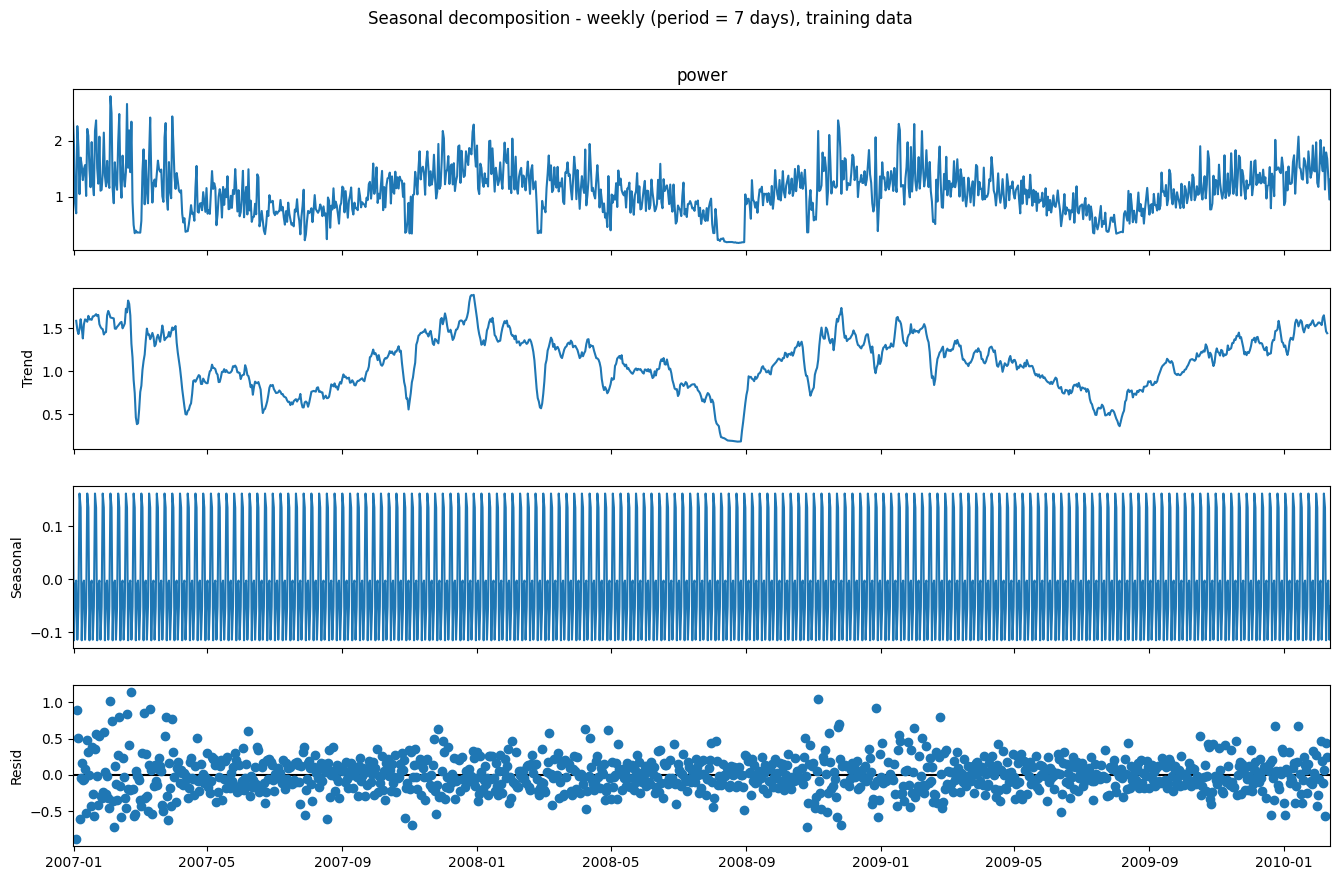

In [10]:
# 1. Weekly decomposition (period = 7 days)
weekly = seasonal_decompose(y_train, model="additive", period=7)
fig = weekly.plot(); fig.set_size_inches(15, 9)
fig.suptitle("Seasonal decomposition - weekly (period = 7 days), training data", y=1.01); plt.show()


In [11]:
# Weekly seasonal effect per weekday
week_effect = weekly.seasonal.groupby(weekly.seasonal.index.dayofweek).mean()
week_effect.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("Weekly seasonal effect (kW above/below the trend):\n", week_effect.round(3))

Weekly seasonal effect (kW above/below the trend):
 Mon   -0.116
Tue   -0.012
Wed   -0.003
Thu   -0.115
Fri   -0.052
Sat    0.162
Sun    0.135
Name: seasonal, dtype: float64


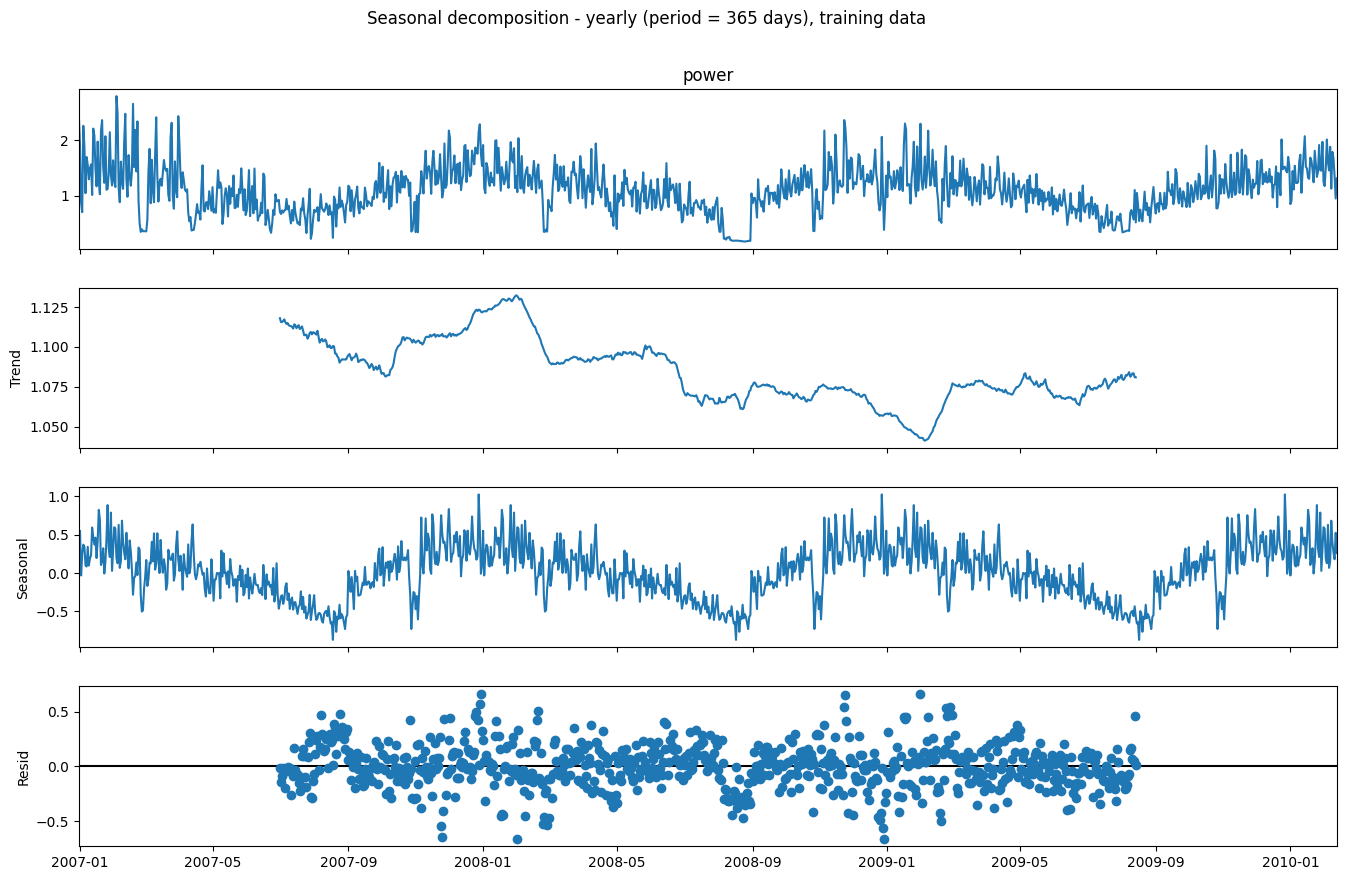

In [12]:
# 2. Yearly decomposition (period = 365 days)
yearly = seasonal_decompose(y_train, model="additive", period=365)
fig = yearly.plot(); fig.set_size_inches(15, 9)
fig.suptitle("Seasonal decomposition - yearly (period = 365 days), training data", y=1.01); plt.show()

In [13]:
print("Yearly seasonal effect range: from", round(yearly.seasonal.min(), 3), "to", round(yearly.seasonal.max(), 3), "kW")
print("Residual std - weekly model:", round(weekly.resid.std(), 3), "| yearly model:", round(yearly.resid.std(), 3))

Yearly seasonal effect range: from -0.87 to 1.021 kW
Residual std - weekly model: 0.243 | yearly model: 0.202


### Interpretation: Seasonal Decomposition

I decomposed the training data into trend, seasonal and residual parts using an additive model, first with a weekly period (7 days) and then with a yearly period (365 days).

Weekly decomposition:
The seasonal part repeats every week. Saturday (+0.162 kW) and Sunday (+0.135 kW) are above the trend, while Monday (-0.116 kW) and Thursday (-0.115 kW) are the lowest days. Tuesday and Wednesday are close to the trend. The weekly effect is fairly small (about plus or minus 0.15 kW) compared with the day-to-day noise in the residuals, which often reach plus or minus 0.5 kW. The weekly trend line still shows the yearly winter and summer wave, because a 7-day average does not remove yearly changes.

Yearly decomposition:
The yearly seasonal pattern is much stronger: it ranges from about -0.87 kW in late summer to +1.02 kW in winter and repeats every year, matching the monthly averages from the EDA. The trend is almost flat (between about 1.04 and 1.13 kW) with a very slight decline, so there is no real long-term trend. The yearly seasonal line looks spiky because with only about three years of training data, each calendar day's seasonal value is an average of only three days, so some daily noise remains. The trend and residuals are missing for the first and last six months, because a 365-day moving average needs half a year of data on each side.

Residuals:
The residual standard deviation is 0.243 kW with the weekly model and 0.202 kW with the yearly model, so the yearly pattern explains more of the variation. However, about 0.2 kW of day-to-day variation remains unexplained, which will limit how accurate any daily forecast can be.

Conclusion: the series is mainly driven by a strong yearly seasonality and a smaller weekly pattern, with no clear long-term trend and a lot of daily noise. The lag_7 feature can capture the weekly pattern, while the rolling mean helps capture the current seasonal level.

## Step 7: Linear Regression – Forecast and Evaluation

In [17]:
results, preds = [], {}

def evaluate(name, y_pred):
    mse = mean_squared_error(y_test, y_pred)
    results.append({"Model": name, "MSE": mse, "RMSE (kW)": np.sqrt(mse),
                    "MAE (kW)": mean_absolute_error(y_test, y_pred), "R²": r2_score(y_test, y_pred)})
    preds[name] = y_pred
    print(f"{name}: MSE = {mse:.4f} | RMSE = {np.sqrt(mse):.4f} kW | MAE = {mean_absolute_error(y_test, y_pred):.4f} kW | R² = {r2_score(y_test, y_pred):.3f}")

def plot_forecast(name, y_pred, color):
    plt.figure(figsize=(15, 4.5))
    plt.plot(y_test.index, y_test, label="Actual", color="black", linewidth=1)
    plt.plot(y_test.index, y_pred, label=f"{name} forecast", color=color, linewidth=1.5)
    plt.title(f"{name}: forecast vs actual (test period)"); plt.ylabel("kW"); plt.legend(); plt.grid(alpha=0.3); plt.show()
    

In [15]:
# Naive baseline: "today = yesterday"
evaluate("Naive (yesterday's value)", X_test["lag_1"].values)

Naive (yesterday's value): MSE = 0.0807 | RMSE = 0.2841 kW | MAE = 0.2026 kW | R² = 0.160


Linear Regression: MSE = 0.0596 | RMSE = 0.2442 kW | MAE = 0.1815 kW | R² = 0.380
Train MSE (Linear Regression): 0.089

Coefficients:
lag_1             0.300
lag_2            -0.076
lag_3             0.139
lag_7             0.113
lag_14            0.147
rolling_mean_7    0.288 
Intercept: 0.095


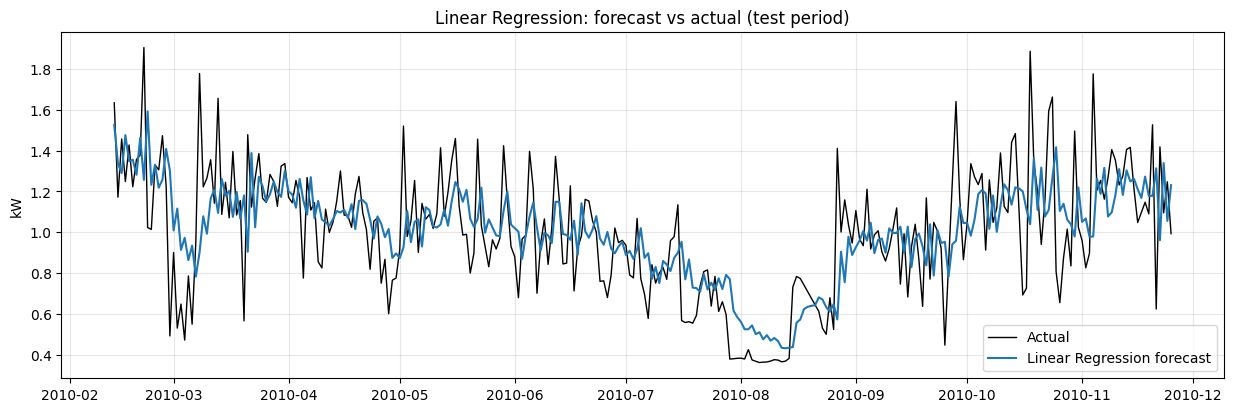

In [16]:
# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
evaluate("Linear Regression", lr.predict(X_test))
print("Train MSE (Linear Regression):", round(mean_squared_error(y_train, lr.predict(X_train)), 4))

print("\nCoefficients:")
print(pd.Series(lr.coef_, index=features).round(3).to_string(), "\nIntercept:", round(lr.intercept_, 3))

plot_forecast("Linear Regression", preds["Linear Regression"], "tab:blue")

### Interpretation: Linear Regression

Baseline:
A naive forecast that simply uses yesterday's value as today's prediction gives an MSE (Mean Squared Error) of 0.0807, an RMSE (Root Mean Squared Error) of 0.284 kW and an R² of 0.160. Any useful model should beat this.

Linear Regression performance:
Linear Regression reached an MSE of 0.0596 on the test set, 26% lower than the naive forecast. The RMSE is 0.244 kW and the MAE (Mean Absolute Error) is 0.182 kW, so a typical forecast is off by about 0.18 to 0.24 kW, around 17 to 22% of the average daily consumption (1.09 kW). R² is 0.380, so the model explains about 38% of the day-to-day variation in the test period. The training MSE (0.089) is higher than the test MSE, so the model is not overfitting. The test period is simply calmer than the training period, which included the very variable winter of 2006 to 2007.

Coefficients:
The model gives the most weight to yesterday's value (lag_1, 0.300) and the average of the previous 7 days (rolling_mean_7, 0.288), followed by lag_14 (0.147), lag_3 (0.139) and lag_7 (0.113). lag_2 has a small negative coefficient (-0.076). This does not mean that consumption two days ago lowers today's consumption. It is a sign of multicollinearity: lag_2 contains almost the same information as lag_1 and the rolling mean.

Forecast vs actual:
The forecast follows the general level and the seasonal shape of the test period well, including the decline into summer and the rise in autumn. However, it smooths out the day-to-day spikes and misses the highest and lowest days. It also reacts late to sudden changes: when consumption dropped to about 0.4 kW in August (probably a holiday), the forecast came down a few days late, and when consumption jumped back up at the end of August, the forecast lagged behind.

Limitations:
- Linear Regression can only learn straight-line relationships between past and future values.
- Because it only uses past values, it can only react after a change has started, so it cannot predict holidays or unusual days in advance.
- The lag features are highly correlated with each other, which makes the coefficients hard to interpret.
- It does not use calendar information (for example, day of the week or holidays) or external factors like temperature, which strongly affect electricity use.

## Step 8: Random Forest – Forecast and Evaluation

Random Forest: MSE = 0.0629 | RMSE = 0.2507 kW | MAE = 0.1858 kW | R² = 0.346
Train MSE (Random Forest): 0.0405

Feature importance (Random Forest):
rolling_mean_7    0.505
lag_1             0.191
lag_14            0.120
lag_7             0.076
lag_2             0.056
lag_3             0.053


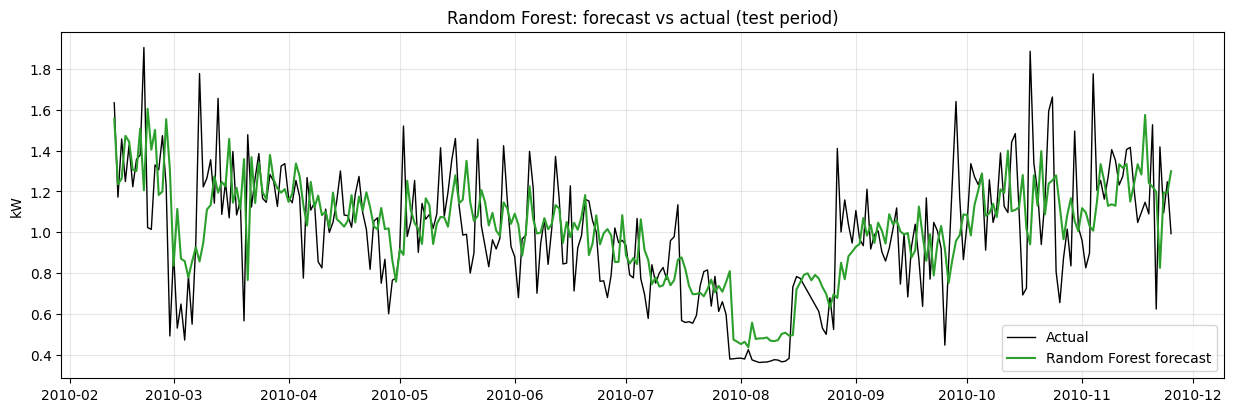

        Model    MSE  RMSE (kW)  MAE (kW)     R²
Random Forest 0.0629     0.2507    0.1858 0.3461


In [18]:
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=random_seed, n_jobs=-1)
rf.fit(X_train, y_train)
evaluate("Random Forest", rf.predict(X_test))
print("Train MSE (Random Forest):", round(mean_squared_error(y_train, rf.predict(X_train)), 4))

print("\nFeature importance (Random Forest):")
print(pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False).round(3).to_string())

plot_forecast("Random Forest", preds["Random Forest"], "tab:green")
print(pd.DataFrame(results).round(4).to_string(index=False))

### Interpretation: Random Forest

Performance:
The Random Forest reached a test MSE of 0.0629 (RMSE 0.251 kW, MAE 0.186 kW, R² 0.346). It is clearly better than the naive forecast (MSE 0.0807), but slightly worse than Linear Regression (MSE 0.0596), about 5% higher.

Overfitting:
The training MSE is 0.0405, much lower than the test MSE of 0.0629. The Random Forest fits the training days very closely but does not generalize as well to new days, which is a sign of overfitting. Linear Regression showed the opposite pattern (training MSE 0.089, higher than its test MSE).

Feature importance:
The 7-day rolling mean is by far the most important feature (0.505), followed by yesterday's value (lag_1, 0.191) and lag_14 (0.120). The other lags (lag_7, lag_2 and lag_3) each contribute between 0.053 and 0.076. The model mainly relies on the recent average level of consumption.

Forecast vs actual:
Like Linear Regression, the Random Forest follows the general level and the seasonal shape but misses the sharp daily spikes and reacts late to sudden changes. A clear difference is visible during the August holiday: actual consumption fell to about 0.38 kW, but the Random Forest forecast stayed at around 0.45 to 0.50 kW. Tree-based models predict averages of values seen in training, so they cannot extrapolate well to levels that rarely appeared in the training data.

Comparison with Linear Regression:
Linear Regression performed slightly better. The relationship between recent days and today's consumption is mostly linear (tomorrow is roughly a weighted average of recent days), plus a lot of random noise. The Random Forest's extra flexibility mainly helped it fit the noise in the training data rather than find real non-linear patterns.

## Step 9: Gradient Boosting (XGBoost) – Forecast, Evaluation and Model Comparison

XGBoost: MSE = 0.0600 | RMSE = 0.2450 kW | MAE = 0.1775 kW | R² = 0.376
Train MSE (XGBoost): 0.0458


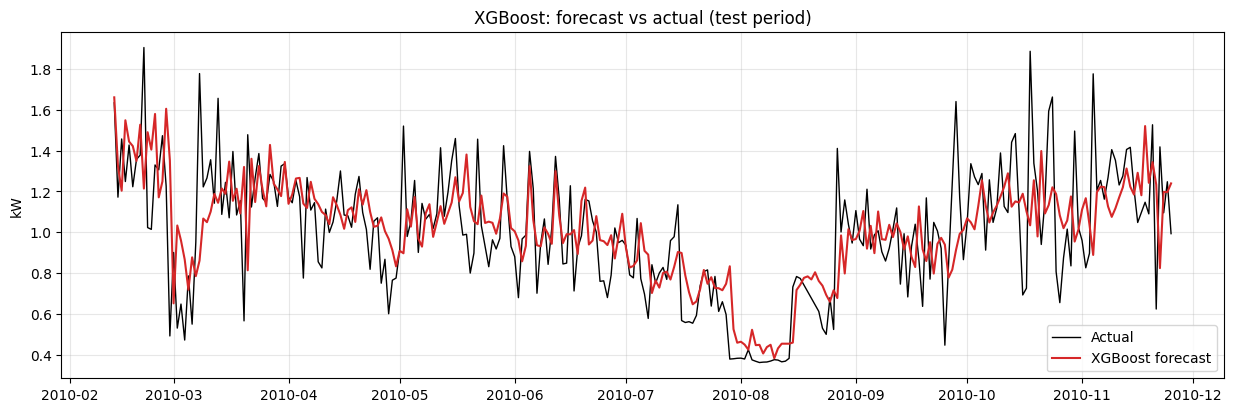

In [19]:
xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                   colsample_bytree=0.8, random_state=random_seed)
xgb.fit(X_train, y_train)
evaluate("XGBoost", xgb.predict(X_test))
print("Train MSE (XGBoost):", round(mean_squared_error(y_train, xgb.predict(X_train)), 4))
plot_forecast("XGBoost", preds["XGBoost"], "tab:red")

In [21]:
# Rebuild the results for all models (avoids missing or duplicated rows from re-running cells)
results, preds = [], {}
evaluate("Naive (yesterday's value)", X_test["lag_1"].values)
evaluate("Linear Regression", lr.predict(X_test))
evaluate("Random Forest", rf.predict(X_test))
evaluate("XGBoost", xgb.predict(X_test))

Naive (yesterday's value): MSE = 0.0807 | RMSE = 0.2841 kW | MAE = 0.2026 kW | R² = 0.160
Linear Regression: MSE = 0.0596 | RMSE = 0.2442 kW | MAE = 0.1815 kW | R² = 0.380
Random Forest: MSE = 0.0629 | RMSE = 0.2507 kW | MAE = 0.1858 kW | R² = 0.346
XGBoost: MSE = 0.0600 | RMSE = 0.2450 kW | MAE = 0.1775 kW | R² = 0.376


In [22]:
# Comparison table
comp = pd.DataFrame(results).drop_duplicates("Model", keep="last").round(4)
comp["MSE vs naive"] = ((comp["MSE"] / comp.loc[comp["Model"].str.startswith("Naive"), "MSE"].values[0] - 1) * 100).round(1).astype(str) + "%"
print("\n" + comp.sort_values("MSE").to_string(index=False))


                    Model    MSE  RMSE (kW)  MAE (kW)     R² MSE vs naive
        Linear Regression 0.0596     0.2442    0.1815 0.3800       -26.1%
                  XGBoost 0.0600     0.2450    0.1775 0.3756       -25.7%
            Random Forest 0.0629     0.2507    0.1858 0.3461       -22.1%
Naive (yesterday's value) 0.0807     0.2841    0.2026 0.1603         0.0%


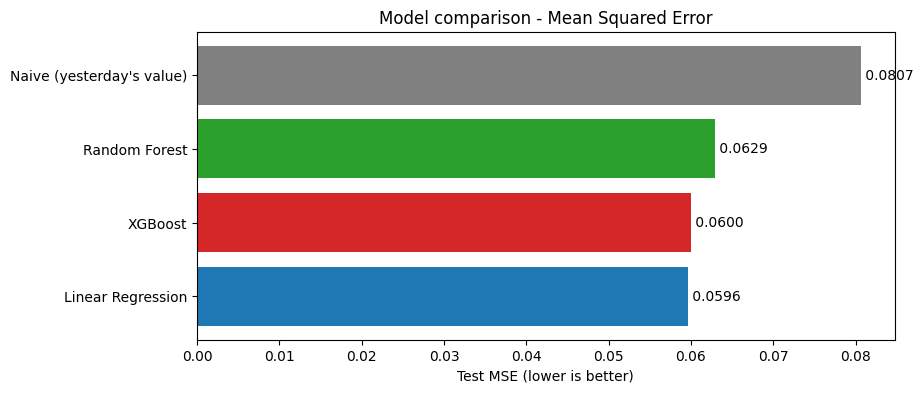

In [26]:
# MSE bar chart
plt.figure(figsize=(9, 4))
order = comp.sort_values("MSE")
colors = {"Linear Regression": "tab:blue", "Random Forest": "tab:green", "XGBoost": "tab:red"}
plt.barh(order["Model"], order["MSE"], color=[colors.get(m, "gray") for m in order["Model"]])
for i, v in enumerate(order["MSE"]):
    plt.text(v, i, f" {v:.4f}", va="center")
plt.xlabel("Test MSE (lower is better)"); plt.title("Model comparison - Mean Squared Error"); plt.show()

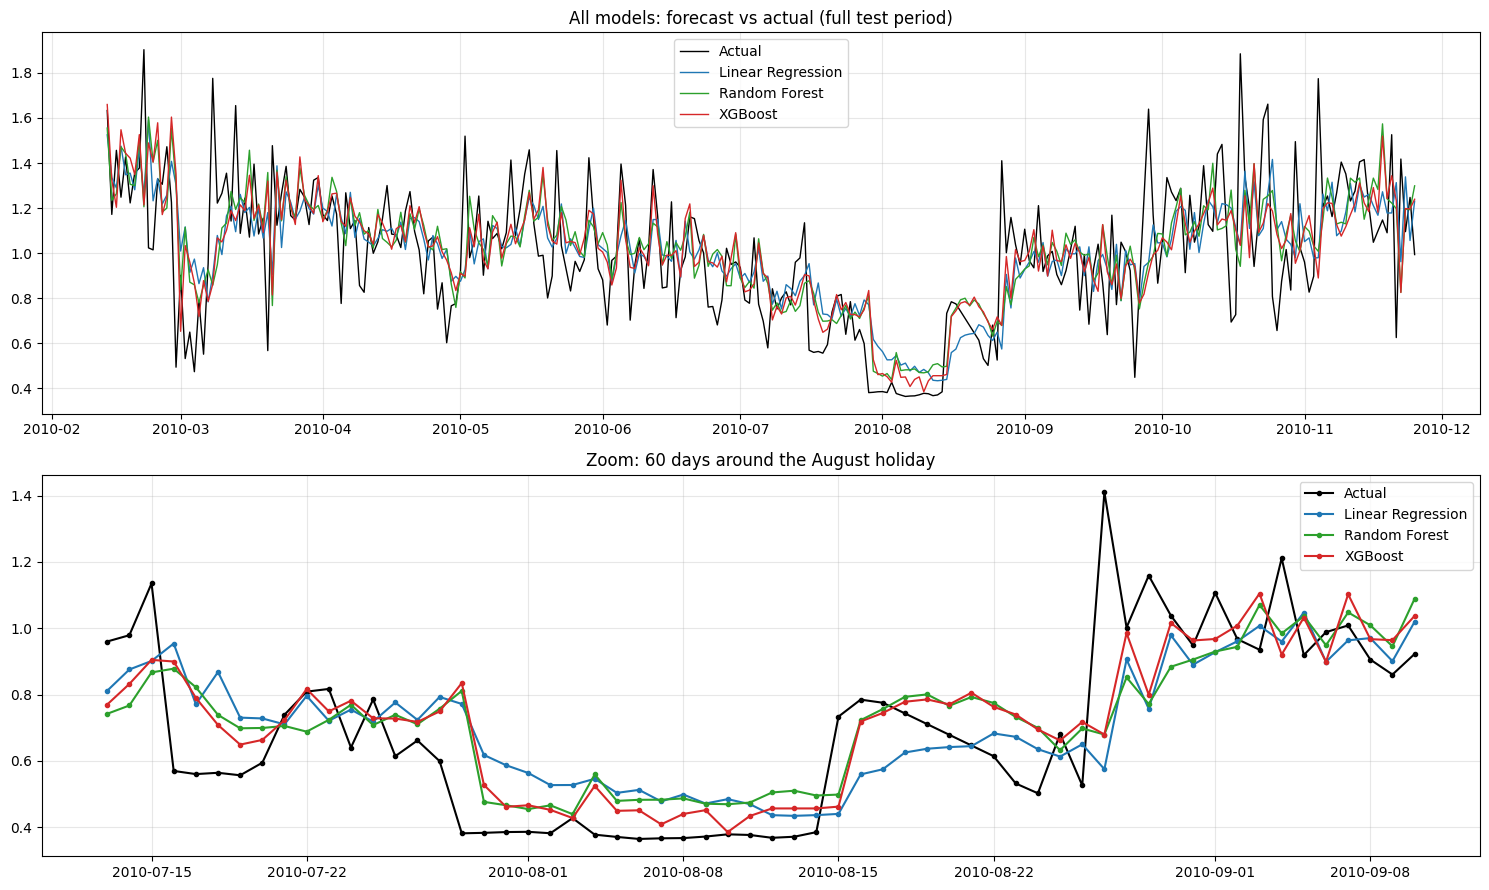

In [24]:
# All forecasts together, zoomed in on 60 days
fig, axes = plt.subplots(2, 1, figsize=(15, 9))
axes[0].plot(y_test.index, y_test, color="black", linewidth=1, label="Actual")
for name, c in [("Linear Regression", "tab:blue"), ("Random Forest", "tab:green"), ("XGBoost", "tab:red")]:
    axes[0].plot(y_test.index, preds[name], color=c, linewidth=1, label=name)
axes[0].set_title("All models: forecast vs actual (full test period)"); axes[0].legend(); axes[0].grid(alpha=0.3)
zoom = slice(150, 210)
axes[1].plot(y_test.index[zoom], y_test.values[zoom], "ko-", markersize=3, label="Actual")
for name, c in [("Linear Regression", "tab:blue"), ("Random Forest", "tab:green"), ("XGBoost", "tab:red")]:
    axes[1].plot(y_test.index[zoom], preds[name][zoom], color=c, marker=".", label=name)
axes[1].set_title("Zoom: 60 days around the August holiday"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Interpretation: XGBoost and Model Comparison

XGBoost performance:
XGBoost reached a test MSE of 0.0600 (RMSE 0.245 kW, MAE 0.178 kW, R² 0.376). Its training MSE is 0.0458, so it overfits somewhat, but less than the Random Forest. Its shallow trees (depth 3), small learning rate and subsampling helped it generalize better.

Comparison of the three models (test MSE, lower is better):
- Linear Regression: 0.0596 (26.1% better than the naive forecast)
- XGBoost: 0.0600 (25.7% better)
- Random Forest: 0.0629 (22.1% better)
- Naive forecast (yesterday's value): 0.0807
All three models clearly beat the naive forecast. Linear Regression has the lowest MSE, but XGBoost is practically tied (a difference of only 0.0004) and has the lowest MAE (0.178 compared with 0.182). This means XGBoost's typical errors are slightly smaller, but it makes a few larger misses, which MSE punishes more. The Random Forest was the weakest of the three, mainly because it overfitted the training data.

Visual comparison:
All three forecasts follow the general level and the seasonal pattern of the test period, and they look very similar. None of them captures the sharp daily spikes. The zoomed view around the August holiday shows clear differences:
- When consumption suddenly dropped to about 0.38 kW at the end of July, all models reacted one day late and then stayed around 0.43 to 0.55 kW, never reaching the real low level.
- When consumption jumped back up around 15 August, the Random Forest and XGBoost forecasts caught up within a day or two, while Linear Regression rose more slowly over several days. The tree models adapt faster to sudden level changes.
- A one-off spike on 27 August (1.41 kW) was missed by all models, because unusual single days cannot be predicted from past values alone.

Conclusion:
Linear Regression performed best by MSE, with XGBoost almost equal. Because the relationship between recent days and the next day is mostly linear and the data is noisy, the more complex tree models did not give a real advantage, and the Random Forest even overfitted.

## Step 10: Report – Time Series Forecasting of Household Power Consumption

### Data and preprocessing
- I used the provided household power consumption dataset (UCI Individual Household Electric Power Consumption): 2,075,259 minute-level readings from December 2006 to November 2010.
- I combined Date and Time into a datetime index, converted the "?" missing values (1.25% of minutes) to NaN, and resampled the minute data to daily average active power (kW), removing the two partial days. This gave 1,440 days. 9 completely missing days were filled by time-based interpolation.
- I created lag features (lag_1, lag_2, lag_3, lag_7, lag_14) and a 7-day rolling mean of previous days, then split the data in time order: the first 80% for training (1,140 days, up to 12 February 2010) and the last 20% for testing (286 days, from 13 February to 25 November 2010).
- Seasonal decomposition of the training data showed a strong yearly seasonality (about -0.87 to +1.02 kW, high in winter and low in summer), a smaller weekly pattern (weekends about +0.15 kW, Mondays and Thursdays about -0.12 kW), no clear long-term trend, and a lot of daily noise (residual standard deviation about 0.2 kW).

### 1. Summary of findings

| Model | MSE | RMSE (kW) | MAE (kW) | R² | Improvement over naive |
|---|---|---|---|---|---|
| **Linear Regression** | **0.0596** | **0.244** | 0.182 | **0.380** | 26.1% |
| XGBoost | 0.0600 | 0.245 | **0.178** | 0.376 | 25.7% |
| Random Forest | 0.0629 | 0.251 | 0.186 | 0.346 | 22.1% |
| Naive (yesterday's value) | 0.0807 | 0.284 | 0.203 | 0.160 | – |

**Visual comparison:** all three models follow the general level and the seasonal shape of the test period (the decline into summer, the August holiday and the rise in autumn), but they smooth out the daily spikes and react about one day late to sudden changes. During the August holiday, none of the models reached the real low level (about 0.38 kW). After the holiday, the tree models (Random Forest and XGBoost) caught up with the jump faster than Linear Regression.

### 2. Model comparison
- **Linear Regression performed best** (lowest MSE, 0.0596, and highest R², 0.380). Electricity use tomorrow is mostly a weighted average of recent days, a linear relationship that this simple model captures well. It did not overfit (its training MSE of 0.089 was higher than its test MSE). Its main weakness is that it reacts slowly to sudden level changes.
- **XGBoost was almost equal** (MSE 0.0600) and had the lowest MAE (0.178). Its shallow trees, small learning rate and subsampling limited overfitting, and it adapted quickly to sudden changes. It needs more tuning and is harder to interpret.
- **Random Forest was the weakest of the three** (MSE 0.0629). It overfitted the training data (training MSE 0.041) and cannot extrapolate beyond the range of the training values, which was visible when it stayed above the real level during the August holiday.
- All three models beat the naive forecast by 22 to 26%, but the differences between them are small. More complex models did not help much because the series is very noisy: daily consumption depends on household behaviour (being away, guests, special days) that past values cannot predict.

### Limitations and possible improvements
- Lag features only use the past, so the models react after a change instead of predicting it.
- Adding calendar features (day of the week, month, holidays) and weather data (temperature) would likely improve the forecasts, especially for the yearly heating pattern and holiday periods.
- Hyperparameter tuning with time-series cross-validation (TimeSeriesSplit) could improve the tree models, and specialised time series models (for example SARIMA or Prophet) could be compared.
- The 9 interpolated days and the household's unusual holiday periods add uncertainty to the results.